In [1]:
import math
import matplotlib.pyplot as plt

def f1(x):
    return 10 - (x - 3)**2

def f2(x):
    return 10 - (-x * math.sin(math.sqrt(abs(x))) + 418.9828872724337)

def f3(x):
    return 10 - (x**2 - 10 * math.cos(2 * math.pi * x) + 10)

FUNCTIONS = {
    "f1": (f1, -5, 10, 3.0, "f1(x): baseline"),
    "f2": (f2, -500, 500, 420.9687, "f2(x): Schwefel (F8)"),
    "f3": (f3, -5.12, 5.12, 0.0, "f3(x): Rastrigin (F9)"),
}

In [2]:
print("OPTIMUM OF EACH FUNCTION")
print(f"{'Function':>9} {'Range':>16} {'Optimum x':>10} {'f(x)':>10}")
print("-" * 49)
for name, (objective, lower, upper, x_opt, title) in FUNCTIONS.items():
    print(f"{name:>9} {f'[{lower}, {upper}]':>16} {x_opt:>10.4f} {objective(x_opt):>10.6f}")

OPTIMUM OF EACH FUNCTION
 Function            Range  Optimum x       f(x)
-------------------------------------------------
       f1         [-5, 10]     3.0000  10.000000
       f2      [-500, 500]   420.9687  10.000000
       f3    [-5.12, 5.12]     0.0000  10.000000


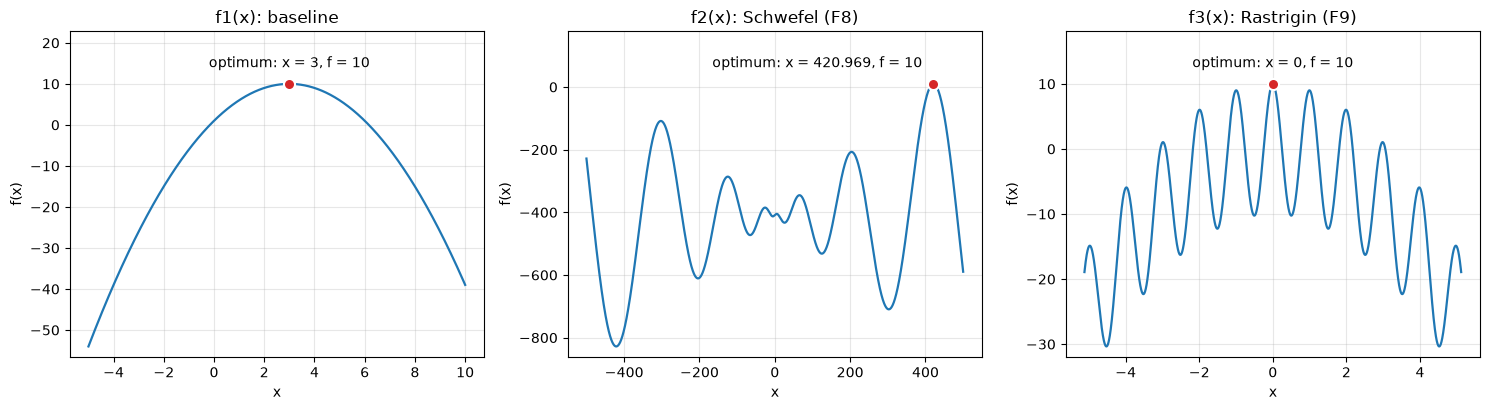

In [3]:
POINTS = 4000

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, (objective, lower, upper, x_opt, title)) in zip(axes, FUNCTIONS.items()):
    xs = [lower + (upper - lower) * i / POINTS for i in range(POINTS + 1)]
    ys = [objective(x) for x in xs]
    ax.plot(xs, ys, color="#1f77b4", linewidth=1.6)
    ax.plot(
        [x_opt],
        [10],
        marker="o",
        color="#d62728",
        markersize=8,
        linestyle="none",
        markeredgecolor="white",
        markeredgewidth=1.5,
        zorder=3
    )
    ax.set_ylim(min(ys) - 0.04 * (10 - min(ys)), 10 + 0.2 * (10 - min(ys)))
    on_right = x_opt > (lower + upper) / 2 + 0.3 * (upper - lower)
    ax.annotate(
        f"optimum: x = {x_opt:g}, f = 10",
        xy=(x_opt, 10),
        xytext=(-8 if on_right else 0, 12),
        textcoords="offset points",
        ha="right" if on_right else "center",
        fontsize=10
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()